# 04. Modélisation Machine Learning (Gradient Boosting / LSTM)

**Projet :** Prévision de l'or (XAU/USD) — *Advanced Time Series* (ENSAI, 3A)

### Objectifs :
1. Ingénierie des caractéristiques temporelles (retards / lags des rendements, moyennes mobiles, volatilité réalisée, RSI, MACD).
2. Intégration des variables exogènes (Dollar Index DXY, VIX, taux 10 ans TNX).
3. Entraînement d'un modèle non-linéaire (Random Forest, LightGBM ou Gradient Boosting).
4. Comparaison des performances avec les modèles économétriques linéaires (ARIMA).

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV


DATA_DIR = Path("../data")
FIG_DIR = Path("../figures")
df = pd.read_csv(DATA_DIR / "gold_daily.csv", parse_dates=["Date"], index_col="Date")
returns = np.log(df["Close"]).diff().dropna()

In [6]:
%pip install statsmodels

  Using cached patsy-1.0.3-py2.py3-none-any.whl.metadata (3.7 kB)
  Using cached formulaic-1.2.2-py3-none-any.whl.metadata (7.0 kB)
  Using cached interface_meta-2.0.1-py3-none-any.whl.metadata (6.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 2.6 MB/s  0:00:04 eta 0:00:01m
Using cached formulaic-1.2.2-py3-none-any.whl (118 kB)
Using cached interface_meta-2.0.1-py3-none-any.whl (15 kB)
Using cached patsy-1.0.3-py2.py3-none-any.whl (233 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [21]:
"""
Gradient boosting sur une série temporelle journalière (cours de l'or)
Cible : rendement log journalier de l'or (stationnaire), pas le prix brut.

Étapes
  0. Config + chargement
  1. Vérifications des données et des "hypothèses"
  2. Construction des features (uniquement avec du passé -> pas de fuite)
  3. Découpage : dev (train + validation par CV temporelle) / test = 3 derniers jours
  4. Baselines (à battre)
  5. Recherche d'hyperparamètres (RandomizedSearchCV + TimeSeriesSplit)
  6. Diagnostic du modèle (résidus, importance des variables)
  7. Évaluation finale sur le test (3 jours)
"""
TEST_SIZE = 3
VAL_SIZE = 20
N_SPLITS = 8
N_LAGS = 10
N_ITER_SEARCH = 40

price = df["Close"].astype(float).sort_index()   # le script travaille sur la série de prix


## N_LAGS = 10 : le nombre de retards

Un retard (lag) est la valeur du rendement k jours avant. Avec N_LAGS = 10, le modèle dispose pour chaque jour t de dix variables explicatives :

ret_lag1  = rendement de la veille (t-1)
ret_lag2  = rendement d'avant-hier (t-2)
...
ret_lag10 = rendement d'il y a 10 jours (t-10)

C'est la « mémoire » que tu donnes au modèle. Comme un arbre n'a pas de notion du temps, il faut lui fournir explicitement le passé sous forme de colonnes.

Trop peu de retards : le modèle manque d'information.
Trop de retards : il apprend du bruit et overfit, d'autant plus que les rendements de l'or sont très bruités.

Pour choisir la valeur, regarde le graphique PACF (diag_series.png) : les retards qui dépassent la bande de confiance sont ceux qui apportent de l'information. Pour des rendements financiers, il y en a souvent très peu, voire aucun. Tu peux aussi traiter N_LAGS comme un hyperparamètre (essayer 3, 5, 10, 20) et comparer les MAE de validation.

Un effet de bord : les 10 premières lignes ont des retards manquants (NaN) et sont supprimées. Plus N_LAGS est grand, plus tu perds de données au début.

## N_SPLITS = 8 : le nombre de folds de validation

Il définit en combien de blocs de validation successifs la validation croisée temporelle découpe tes données. Avec VAL_SIZE = 20, on obtient 8 blocs de 20 jours, placés à la fin de la période de dev :

fold 1 : [████████████████████ train ████████████] [val 20j]

fold 2 : [█████████████████████████ train ████████████] [val 20j]

fold 3 : [██████████████████████████████ train ████████] [val 20j]

...

fold 8 : [███████████████████████████████████████ train ] [val 20j]

C'est une fenêtre expansive : le train grossit à chaque fold, et la validation est toujours après le train, comme en situation réelle.

Pourquoi 8 plutôt que 1 ? Un seul bloc de validation te donnerait un score très dépendant de la période choisie (un mois calme ou un mois agité). En moyennant sur 8 blocs, tu obtiens une estimation plus stable. Pour un nombre de folds plus élevé, le coût est celui du temps de calcul, car chaque combinaison d'hyperparamètres est entraînée autant de fois qu'il y a de folds. Ici : 40 combinaisons × 8 folds = 320 entraînements.

Tu peux aussi remarquer que seuls les N_SPLITS × VAL_SIZE derniers jours (160 jours ici) servent de validation. Les folds ne couvrent donc pas tout l'historique, et c'est voulu : les périodes récentes sont les plus représentatives de ce que le modèle devra prédire.

1. VÉRIFICATIONS
Période : 2005-01-03 -> 2026-11-24 (5505 jours)
Valeurs manquantes : 0
Dates dupliquées   : 0
Index trié         : True
Prix <= 0          : 0
Écarts entre dates (jours) :
 Date
1.0    4311
3.0     989
4.0     150
2.0      51
5.0       3
log(prix)    ADF p=0.6167 (stationnaire si < 0.05) | KPSS p=0.0100 (stationnaire si > 0.05)
log-rendement ADF p=0.0000 (stationnaire si < 0.05) | KPSS p=0.1000 (stationnaire si > 0.05)

Ljung-Box rendements    (lag 10) p=0.0172  (< 0.05 : autocorrélation linéaire)
Ljung-Box rendements^2  (lag 10) p=0.0000  (< 0.05 : clusters de volatilité)


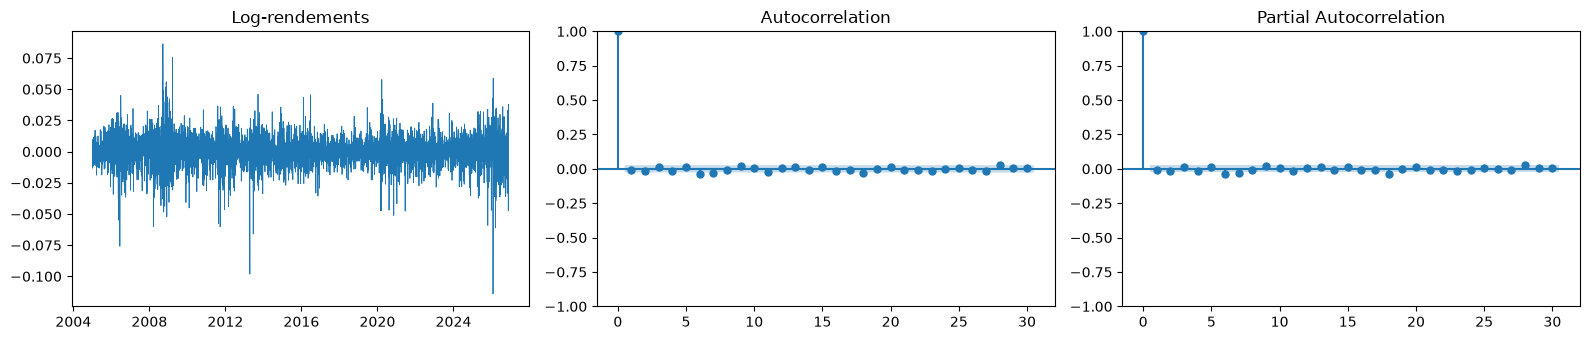

In [22]:
# ----------------------------------------------------------------------------
# 1. VÉRIFICATIONS
# ----------------------------------------------------------------------------
print("=" * 70, "\n1. VÉRIFICATIONS\n", "=" * 70)

# 1.1 Qualité des données
print(f"Période : {price.index.min().date()} -> {price.index.max().date()} ({len(price)} jours)")
print("Valeurs manquantes :", price.isna().sum())
print("Dates dupliquées   :", price.index.duplicated().sum())
print("Index trié         :", price.index.is_monotonic_increasing)
print("Prix <= 0          :", (price <= 0).sum())
gaps = price.index.to_series().diff().dt.days.value_counts().head(5)
print("Écarts entre dates (jours) :\n", gaps.to_string())
price = price[~price.index.duplicated()].dropna()

log_ret = np.log(price).diff().dropna()

# 1.2 Stationnarité : le prix ne l'est pas, le rendement doit l'être.
#     Les arbres ne savent pas extrapoler hors de la plage vue à l'entraînement,
#     d'où l'intérêt de modéliser des rendements plutôt que des niveaux.
def stationarity_report(s, name):
    adf_p = adfuller(s, autolag="AIC")[1]           # H0 : racine unitaire (non stationnaire)
    kpss_p = kpss(s, regression="c", nlags="auto")[1]  # H0 : stationnaire
    print(f"{name:12s} ADF p={adf_p:.4f} (stationnaire si < 0.05) | "
          f"KPSS p={kpss_p:.4f} (stationnaire si > 0.05)")

stationarity_report(np.log(price), "log(prix)")
stationarity_report(log_ret, "log-rendement")

# 1.3 Autocorrélation : combien de retards sont utiles ? Y a-t-il de la structure à capter ?
lb = acorr_ljungbox(log_ret, lags=[10], return_df=True)
lb2 = acorr_ljungbox(log_ret ** 2, lags=[10], return_df=True)
print(f"\nLjung-Box rendements    (lag 10) p={lb['lb_pvalue'].iloc[0]:.4f}  (< 0.05 : autocorrélation linéaire)")
print(f"Ljung-Box rendements^2  (lag 10) p={lb2['lb_pvalue'].iloc[0]:.4f}  (< 0.05 : clusters de volatilité)")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
ax[0].plot(log_ret.index, log_ret.values, lw=0.6); ax[0].set_title("Log-rendements")
plot_acf(log_ret, lags=30, ax=ax[1]); plot_pacf(log_ret, lags=30, ax=ax[2])
plt.tight_layout(); plt.savefig("diag_series.png", dpi=120)

### Qualité des données

Les 5 505 jours sur près de 22 ans correspondent à environ 252 jours de bourse par an, donc il n'en manque pas. Les écarts de dates s'expliquent par le calendrier :

1 jour : jours de bourse consécutifs.
3 jours : week-ends (989 fois).
4 jours : week-ends allongés par un férié le lundi ou le vendredi (150 fois).
2 jours : fériés en milieu de semaine (51 fois).
5 jours : 3 cas isolés, typiquement Noël ou Nouvel An collés à un week-end. Ils méritent un coup d'œil, mais rien d'anormal.
Stationnarité

Le prix n'est pas stationnaire : l'ADF ne rejette pas la racine unitaire (p = 0,62) et le KPSS rejette la stationnarité (p = 0,01). Les log-rendements le sont, selon les deux tests (ADF p ≈ 0, KPSS p = 0,10). Ça confirme qu'il faut modéliser les rendements, comme dans le script. (Les p-values du KPSS sont plafonnées à 0,01 et 0,10 par statsmodels, ce n'est pas une erreur.)

### Autocorrélation
Rendements (p = 0,017) : il y a une autocorrélation linéaire statistiquement significative, mais faible. Avec 5 500 observations, le test détecte des effets minuscules. Ça ne veut pas dire qu'elle soit exploitable. Regarde le PACF dans diag_series.png pour voir quels retards dépassent la bande de confiance. Je m'attends à très peu de retards, avec des valeurs proches de 0,05.
Rendements au carré (p ≈ 0) : il y a des clusters de volatilité très marqués. Les périodes agitées (2008, 2011, 2020…) sont suivies de périodes agitées, et inversement. C'est le résultat le plus important de tes tests.
### Ce que ça change pour ton modèle
La volatilité est la partie prévisible de la série. Les features de volatilité (ret_std_5/20/60/250, vol_ratio) vont probablement peser plus que les retards de rendements. C'est là que les fenêtres longues dont on parlait ont du sens.
Les erreurs seront dominées par les périodes agitées. Une journée de krach pèse bien plus dans le MAE ou le RMSE qu'une journée calme. Deux options : passer à loss="absolute_error" dans HistGradientBoostingRegressor (moins sensible aux extrêmes), ou analyser les erreurs par régime de volatilité.

Tu as assez de données pour une validation plus solide. Avec 5 500 lignes, 8 folds de 20 jours ne couvrent que les 160 derniers jours, soit un seul régime de marché. Je te conseille N_SPLITS = 10 et VAL_SIZE = 60, soit 600 jours de validation répartis sur plusieurs régimes. Le temps de calcul reste raisonnable.
Reste réaliste sur la direction. Avec un effet linéaire faible, ne t'attends pas à une direction nettement meilleure que 50 %. Le gain le plus probable est sur l'amplitude des mouvements.

In [23]:
# ----------------------------------------------------------------------------
# 2. FEATURES (uniquement construites avec des informations connues AVANT t)
# ----------------------------------------------------------------------------
def build_dataset(price: pd.Series):
    p = price
    r = np.log(p).diff()
    past_r = r.shift(1)                       # tout est décalé d'un jour : pas de fuite
    f = pd.DataFrame(index=p.index)
    for k in range(1, N_LAGS + 1):
        f[f"ret_lag{k}"] = r.shift(k)
    for w in (5, 10, 20):
        f[f"ret_mean_{w}"] = past_r.rolling(w).mean()
        f[f"ret_std_{w}"] = past_r.rolling(w).std()
    f["mom_10"] = np.log(p.shift(1) / p.shift(11))
    f["dist_ma20"] = np.log(p.shift(1) / p.shift(1).rolling(20).mean())
    f["dow"] = p.index.dayofweek
    data = f.join(r.rename("target")).dropna()
    return data.drop(columns="target"), data["target"]

X, y = build_dataset(price)

# 1.4 Test anti-fuite : les features ne doivent pas changer si on supprime le futur
X_trunc, _ = build_dataset(price.iloc[:-30])
common = X_trunc.index
assert np.allclose(X.loc[common].values, X_trunc.values, equal_nan=True), "FUITE DE DONNÉES détectée !"
print("\nTest anti-fuite : OK (les features à t n'utilisent que le passé)")



Test anti-fuite : OK (les features à t n'utilisent que le passé)


In [24]:
# 3. DÉCOUPAGE
#    |------------- dev (train + validation par CV) -------------|-- test (3 j) --|
#    Validation = plusieurs blocs successifs de VAL_SIZE jours (fenêtre expansive)
# ----------------------------------------------------------------------------
X_dev, y_dev = X.iloc[:-TEST_SIZE], y.iloc[:-TEST_SIZE]
X_test, y_test = X.iloc[-TEST_SIZE:], y.iloc[-TEST_SIZE:]
assert X_dev.index.max() < X_test.index.min()

tscv = TimeSeriesSplit(n_splits=N_SPLITS, test_size=VAL_SIZE)
print("\n3. DÉCOUPAGE")
print(f"Dev  : {X_dev.index.min().date()} -> {X_dev.index.max().date()} ({len(X_dev)} j)")
print(f"Test : {X_test.index.min().date()} -> {X_test.index.max().date()} ({len(X_test)} j)")
for i, (tr, va) in enumerate(tscv.split(X_dev)):
    print(f"  fold {i+1}: train {X_dev.index[tr[0]].date()}->{X_dev.index[tr[-1]].date()} "
          f"| val {X_dev.index[va[0]].date()}->{X_dev.index[va[-1]].date()}")



3. DÉCOUPAGE
Dev  : 2005-02-02 -> 2026-11-19 (5481 j)
Test : 2026-11-20 -> 2026-11-24 (3 j)
  fold 1: train 2005-02-02->2026-04-02 | val 2026-04-06->2026-05-01
  fold 2: train 2005-02-02->2026-05-01 | val 2026-05-04->2026-06-01
  fold 3: train 2005-02-02->2026-06-01 | val 2026-06-02->2026-06-30
  fold 4: train 2005-02-02->2026-06-30 | val 2026-07-01->2026-07-29
  fold 5: train 2005-02-02->2026-07-29 | val 2026-07-30->2026-08-26
  fold 6: train 2005-02-02->2026-08-26 | val 2026-08-27->2026-09-24
  fold 7: train 2005-02-02->2026-09-24 | val 2026-09-25->2026-10-22
  fold 8: train 2005-02-02->2026-10-22 | val 2026-10-23->2026-11-19


In [25]:
# ----------------------------------------------------------------------------
# 4. BASELINES (le modèle doit faire mieux, sinon il ne sert à rien)
# ----------------------------------------------------------------------------
def oof_predictions(model_or_none, kind="model"):
    """Prédictions hors-échantillon sur tous les blocs de validation."""
    preds, trues, idxs = [], [], []
    for tr, va in tscv.split(X_dev):
        if kind == "zero":
            p = np.zeros(len(va))
        elif kind == "mean":
            p = np.full(len(va), y_dev.iloc[tr].mean())
        else:
            m = clone(model_or_none).fit(X_dev.iloc[tr], y_dev.iloc[tr])
            p = m.predict(X_dev.iloc[va])
        preds.append(p); trues.append(y_dev.iloc[va].values); idxs.append(y_dev.index[va])
    return np.concatenate(preds), np.concatenate(trues), np.concatenate(idxs)

def metrics(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "Dir.acc": np.mean(np.sign(y_true) == np.sign(y_pred))}

print("\n4. BASELINES (validation, hors-échantillon)")
base_rows = {}
for kind in ("zero", "mean"):
    p, t, _ = oof_predictions(None, kind)
    base_rows[f"baseline_{kind}"] = metrics(t, p)
print(pd.DataFrame(base_rows).T.round(6))


4. BASELINES (validation, hors-échantillon)
                    MAE      RMSE  Dir.acc
baseline_zero  0.011099  0.014397  0.00625
baseline_mean  0.011125  0.014450  0.47500


Ce tableau donne le score à battre. Un modèle n'a de valeur que s'il fait mieux que ces deux prévisions « naïves », calculées sur les mêmes blocs de validation que ton gradient boosting.

### Les deux baselines
baseline_zero : on prédit un rendement nul tous les jours (« le prix ne bouge pas »). C'est l'équivalent, sur les rendements, de la marche aléatoire sur les prix.
baseline_mean : on prédit chaque jour le rendement moyen observé sur le train du fold, soit une petite dérive positive.

### Les colonnes

MAE (erreur absolue moyenne) : en moyenne, la prévision se trompe de 1,11 % par jour. C'est l'ordre de grandeur de la volatilité quotidienne de l'or, ce qui est normal, car ces baselines ne prédisent rien.

RMSE : même idée, mais les grosses erreurs pèsent davantage. Il vaut 1,44 %. Le rapport RMSE/MAE vaut ≈ 1,30, alors qu'il serait de 1,25 pour une loi normale. Cet écart indique des queues un peu épaisses, c'est-à-dire quelques jours extrêmes.

Dir.acc (précision directionnelle) : part des jours où le signe prédit est le bon.

### Ce qu'il faut en retenir

1. La précision directionnelle du zero (0,006) n'a aucun sens. Le signe de 0 vaut 0, donc il n'est jamais égal au signe d'un rendement, sauf les rares jours où le rendement est exactement nul (1 jour sur 160 ici). Ignore cette ligne.

2. Les deux baselines sont quasi identiques, et zero est même un peu meilleure (MAE 0,011099 contre 0,011125). La moyenne historique n'apporte rien. Autrement dit, la dérive de l'or est trop faible pour être exploitable sur 20 jours, et il est inutile d'essayer de la prédire.

3. Le 0,475 de la baseline mean ne signifie pas qu'elle se trompe de direction. Elle prédit toujours « hausse » (la moyenne est positive), donc ce chiffre est simplement la part de jours de baisse dans les blocs de validation. Sur 160 jours, l'incertitude est d'environ ±4 points, donc 47,5 % n'est pas distinguable de 50 %.